<a href="https://colab.research.google.com/github/carn51/Assignment-1/blob/main/fyp_12_10_26_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Code all mine, from earlier notebook

[https://colab.research.google.com/drive/1gk37Ev1CgAbAF2v_v5PGpYFL6guaCny4#scrollTo=YAROGB5z-EfX](https://)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from scipy.stats import kurtosis
import numpy as np
import seaborn as sns

In [2]:
df = pd.DataFrame(pd.read_csv('/content/Schizophrenia _Dataset(5).csv'))
df.head()

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Race,Rumination,Sex,Sleep,Stress,Suspicious,Tension,Tired,Unusual_Thought,Withdrawal
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,8.305502,...,White,5.041432,Female,6.552082,5.915492,3.991749,6.371877,4.537270,3.744410,5.242819
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,5.060206,...,White,4.656790,Male,5.558434,4.008265,NaN,2.238665,6.113746,0.720458,3.797242
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,6.504229,...,Black,7.290494,Female,5.787561,7.177926,NaN,6.992499,5.557374,-0.491255,4.421288
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,No,1.380185,8.943851,6.994948,...,White,6.759339,Female,6.787287,2.866815,NaN,4.018286,6.136269,0.765388,2.299562
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,Yes,1.237976,6.741627,5.869212,...,Black,6.190019,Male,7.748312,6.798220,5.103103,5.063542,4.213723,0.705895,6.547707


Brief overview

In [4]:
df.shape

(5000, 27)

In [3]:
df.describe()

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delusion,Dep_Mood,Focus,Hallucination,...,Pregnant,Psychomotor,Rumination,Sleep,Stress,Suspicious,Tension,Tired,Unusual_Thought,Withdrawal
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,...,2762.000000,5000.000000,5000.000000,5000.000000,5000.000000,2127.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.505800,6.502860,2.478849,27.070029,6.519924,0.279407,2.637389,5.727062,6.519924,65.073832,...,0.101376,4.680583,5.685816,7.011266,4.916418,2.754909,4.920667,inf,2.480266,3.958121
std,0.500016,1.488151,1.730810,14.202618,1.474846,0.834494,1.440347,3.284501,1.474846,223.943469,...,0.301880,1.482692,2.161891,1.410841,2.220262,1.496126,1.962342,NaN,1.410475,1.469444
min,0.000000,1.098854,-3.211011,0.141074,1.299964,0.000187,-2.127037,0.000000,1.299964,0.027350,...,0.000000,-0.024974,-0.409032,2.144726,-3.257788,-2.346238,-2.183456,0.366650,-1.981307,-0.825919
25%,0.000000,5.495361,1.265128,16.724108,5.528181,0.018655,1.629919,4.678095,5.528181,4.113962,...,0.000000,3.697870,4.042552,6.058402,3.443683,1.703462,3.565482,4.491580,1.486439,2.969534
50%,1.000000,6.485527,2.427409,25.165292,6.498042,0.064259,2.558146,6.752196,6.498042,12.764604,...,0.000000,4.720156,5.521805,6.980519,5.096416,2.735108,5.247353,5.513508,2.388994,3.962131
75%,1.000000,7.489218,3.642059,35.447666,7.519759,0.215773,3.588012,8.045706,7.519759,41.814204,...,0.000000,5.682627,7.276673,7.977138,6.531673,3.725759,6.385145,6.569176,3.426667,4.972302
max,1.000000,11.603140,8.803433,113.438734,11.649649,21.001327,8.978785,12.003550,11.649649,6287.163151,...,1.000000,10.171540,12.009666,11.920312,11.970952,8.212275,9.622076,inf,8.066822,9.022207


AS FUNCS TO REPEAT

0.044007407407407405% of cells are missing
Missingness:  
Intrusive_Thoughts     830
Pregnant              2238
Suspicious            2873
dtype: int64
Proportion of rows with more than 2 missing values that are schizophrenic:  0.4904
Versus overall proportion of schizophrenics:  0.5058


/tmp/ipykernel_858/1870045862.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(nulls_column[item])
/tmp/ipykernel_858/1870045862.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  missing_col_list = nulls_column[item].keys()


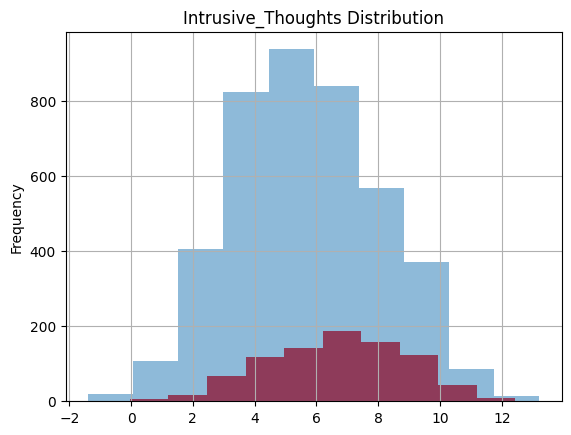

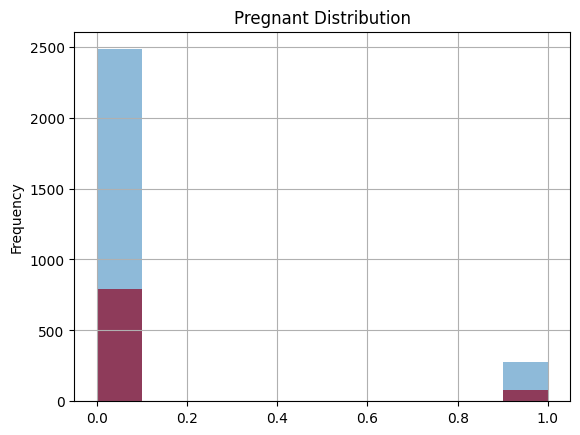

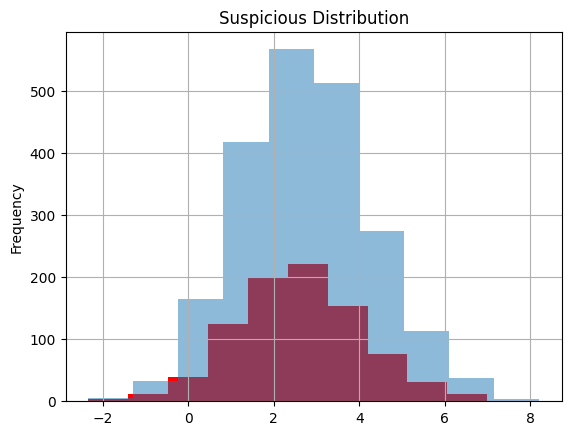

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Psychomotor,Race,Rumination,Sex,Sleep,Stress,Tension,Tired,Unusual_Thought,Withdrawal
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,8.305502,...,3.854579,White,5.041432,Female,6.552082,5.915492,6.371877,4.537270,3.744410,5.242819
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,5.060206,...,5.821110,White,4.656790,Male,5.558434,4.008265,2.238665,6.113746,0.720458,3.797242
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,6.504229,...,7.893102,Black,7.290494,Female,5.787561,7.177926,6.992499,5.557374,-0.491255,4.421288
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,No,1.380185,8.943851,6.994948,...,3.812874,White,6.759339,Female,6.787287,2.866815,4.018286,6.136269,0.765388,2.299562
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,Yes,1.237976,6.741627,5.869212,...,5.119658,Black,6.190019,Male,7.748312,6.798220,5.063542,4.213723,0.705895,6.547707
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0,7.860754,2.336196,19.357732,6.025528,0.010833,Yes,1.943012,10.131561,6.025528,...,4.679741,Hispanic,8.431264,Female,5.070006,3.660955,3.545347,4.552549,2.427987,2.622951
4996,0,10.172056,1.385703,12.605660,4.513683,0.191444,Yes,0.443218,6.935870,4.513683,...,3.854358,Black,5.391609,Female,8.067497,8.071709,6.263030,1.482647,2.649173,2.090298
4997,1,4.880272,0.311701,39.005728,6.817671,0.003989,Yes,3.770044,5.107938,6.817671,...,5.224816,Black,4.959354,Male,6.460624,8.691664,6.573167,4.382728,0.183887,7.550087
4998,1,7.288783,4.135178,38.522660,7.611236,0.123641,No,0.703623,5.528039,7.611236,...,5.834768,Asian,4.915460,Female,8.015376,7.094015,7.059948,4.230738,3.460764,-0.163929


In [32]:
def cleaning_and_missingness_func(df):

  proportion_missing_values = df.isnull().sum().sum() / (df.shape[0] * df.shape[1])
  print(f'{proportion_missing_values}% of cells are missing')

  nulls_column = df.isnull().sum()
  #null_col_values = nulls_column.values
  high_missing_columns_index = np.where(nulls_column.values > 100)
  print('Missingness:  ')
  for item in high_missing_columns_index:
    print(nulls_column[item])

  two_plus_missing_cols = df.mask(df.isnull().sum(axis = 1) > 2)
  print(f'Proportion of rows with more than 2 missing values that are schizophrenic:  {two_plus_missing_cols['Diagnosis'].sum() / df.shape[0]}')
  print(f'Versus overall proportion of schizophrenics:  {df['Diagnosis'].sum() / df.shape[0]}')

  #accessing missingness columns from hardcoded
  missing_col_list = nulls_column[item].keys()

  for missing_col in missing_col_list:
    plt.title(f'{missing_col} Distribution')
    plt.ylabel('Frequency')
    df.dropna()[missing_col].hist(color = 'red')
    two_plus_missing_cols[missing_col].hist(alpha = 0.5)
    plt.show()

  df = df.drop(columns = missing_col_list)
  return df

cleaning_and_missingness_func(df)

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Rumination,Sex,Sleep,Stress,Suspicious,Tension,Tired,Unusual_Thought,Withdrawal,ID
1727,0,11.288607,0.314455,22.281110,6.535779,0.074097,No,0.513200,0.000000,6.535779,...,10.599673,Female,7.628965,4.024827,NaN,2.844018,5.062663,-0.315859,2.632904,1727
1865,0,11.603140,1.128291,30.286102,7.584974,0.186164,No,0.447183,7.766037,7.584974,...,8.648874,Female,7.101698,4.952958,NaN,4.027466,7.190131,1.750675,5.157132,1865
2102,0,11.326136,0.471849,48.001121,6.116657,0.132815,No,1.714730,0.000000,6.116657,...,9.278940,Female,5.893279,4.472117,NaN,3.128726,5.762602,0.138995,5.005872,2102
2666,0,11.255475,0.417478,19.407577,7.087778,0.014976,Yes,1.390472,9.134040,7.087778,...,4.065332,Male,6.637107,2.314909,NaN,1.532838,5.384118,-0.535850,3.516735,2666
2699,0,11.378754,1.837023,30.859452,7.258015,0.410995,Yes,4.159998,8.513310,7.258015,...,3.728205,Male,6.298757,1.951504,1.675804,3.545074,4.788719,0.906728,2.597398,2699
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1946,1,7.037175,7.443897,38.421958,5.595710,0.011906,Yes,3.619649,0.000000,5.595710,...,3.051894,Male,6.458187,3.298820,NaN,5.528268,5.468059,5.017221,8.480746,1946
2679,1,7.165833,1.835799,12.318433,7.290123,0.040339,Yes,3.867122,9.837023,7.290123,...,2.177791,Male,6.902727,5.761274,NaN,5.161775,2.484063,3.448059,8.549491,2679
2821,1,8.112008,2.029541,15.749570,7.136619,0.016588,No,6.054157,5.653432,7.136619,...,4.045282,Male,7.434573,4.476539,NaN,5.681477,6.728447,3.268935,9.022207,2821
3053,1,7.184740,7.799039,17.846095,7.974002,0.208173,Yes,4.394719,8.312165,7.974002,...,3.253363,Male,7.743037,7.446947,NaN,7.126585,5.903702,5.866849,8.411491,3053


Value Counts
ID
55      2
1267    2
4981    2
4080    2
3053    2
       ..
1904    1
1946    1
2679    1
2821    1
3711    1
Name: count, Length: 234, dtype: int64
Axes(0.125,0.11;0.62x0.77)
PROCEED WITH:  


,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Rumination,Sex,Sleep,Stress,Suspicious,Tension,Tired,Unusual_Thought,Withdrawal,ID
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,8.305502,...,5.041432,Female,6.552082,5.915492,3.991749,6.371877,4.537270,3.744410,5.242819,0
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,5.060206,...,4.656790,Male,5.558434,4.008265,NaN,2.238665,6.113746,0.720458,3.797242,1
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,6.504229,...,7.290494,Female,5.787561,7.177926,NaN,6.992499,5.557374,-0.491255,4.421288,2
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,No,1.380185,8.943851,6.994948,...,6.759339,Female,6.787287,2.866815,NaN,4.018286,6.136269,0.765388,2.299562,3
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,Yes,1.237976,6.741627,5.869212,...,6.190019,Male,7.748312,6.798220,5.103103,5.063542,4.213723,0.705895,6.547707,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0,7.860754,2.336196,19.357732,6.025528,0.010833,Yes,1.943012,10.131561,6.025528,...,8.431264,Female,5.070006,3.660955,NaN,3.545347,4.552549,2.427987,2.622951,4995
4996,0,10.172056,1.385703,12.605660,4.513683,0.191444,Yes,0.443218,6.935870,4.513683,...,5.391609,Female,8.067497,8.071709,3.933825,6.263030,1.482647,2.649173,2.090298,4996
4997,1,4.880272,0.311701,39.005728,6.817671,0.003989,Yes,3.770044,5.107938,6.817671,...,4.959354,Male,6.460624,8.691664,NaN,6.573167,4.382728,0.183887,7.550087,4997
4998,1,7.288783,4.135178,38.522660,7.611236,0.123641,No,0.703623,5.528039,7.611236,...,4.915460,Female,8.015376,7.094015,1.884874,7.059948,4.230738,3.460764,-0.163929,4998


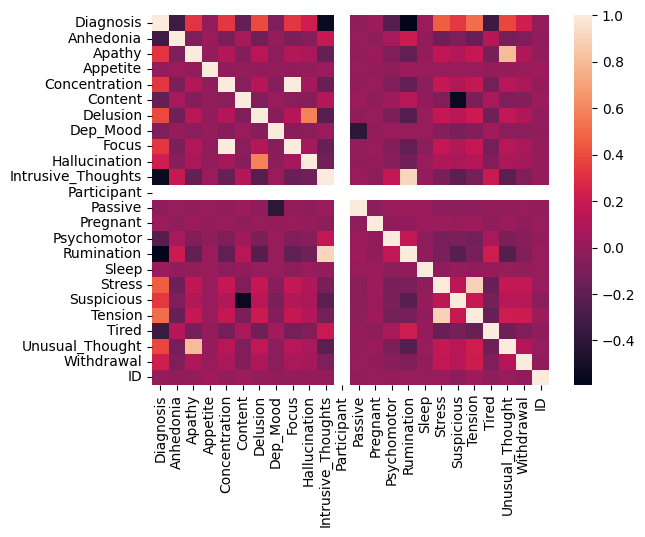

In [48]:
def EDA_func(df):

  df['ID'] = np.arange(0, len(df.index), 1)

  df_num = df.select_dtypes(include = ['number'])

  def univariate_outliers_df(df_num, col):
    outliers = []
    for idx, val in enumerate(df_num[col]):
      if val > (df_num[col].mean() + (3 * df_num[col].std())):
        #as a check of number
        outliers.append(idx)
    return df_num.iloc[outliers]

  outlier_df_list = []

  for cols in df_num.columns:
    outlier_df_list.append(univariate_outliers_df(df, cols))

  outlier_df_final = pd.concat(outlier_df_list, axis = 0)
  display(outlier_df_final)
  outlier_df_final_list = list(outlier_df_final['ID'])
  print('Value Counts')
  print(outlier_df_final['ID'].value_counts())

  df['Tired'].idxmax()
  df = df[df['ID'] != 153]

  outlier_index = set(outlier_df_final['ID'])
  df = df.drop(outlier_index, axis = 'index')

  multicoll = sns.heatmap(df.select_dtypes(include = ['number']).corr())
  print(multicoll)

  #ensure it returns non  outlier df
  print('PROCEED WITH:  ')
  return df[~df['ID'].isin(outlier_df_final)]

EDA_func(df)

(array([ 0,  6, 10, 15, 17, 19]),)
(array([1]),)
(array([ 2, 21]),)
(array([3]),)
(array([4, 8]),)
(array([5]),)
(array([6, 9]),)
(array([ 7, 12]),)
(array([8]),)
(array([9]),)
(array([10, 15]),)
(array([], dtype=int64),)
(array([12]),)
(array([13]),)
(array([14]),)
(array([15]),)
(array([16]),)
(array([17, 19]),)
(array([18]),)
(array([19]),)


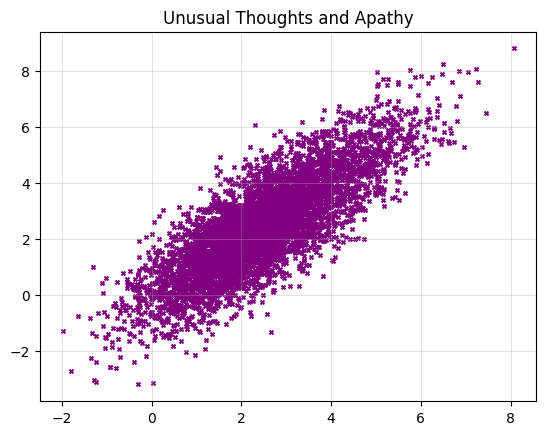

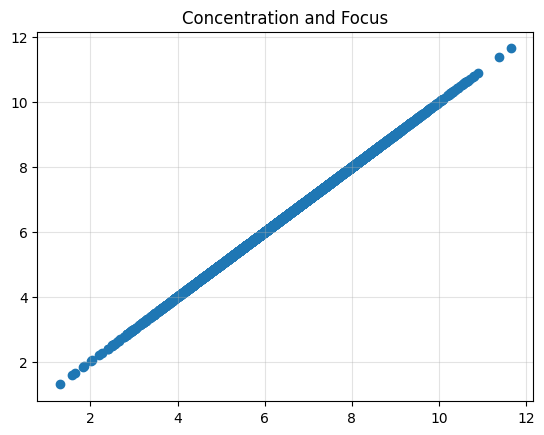

In [49]:
mcl_matrix = df.select_dtypes(include = ['number']).corr()
high_corr = np.abs(np.triu(mcl_matrix)) > 0.4

for row in range(0, 20):
  print(np.where(high_corr[row]))

plt.title('Unusual Thoughts and Apathy')
plt.grid(alpha = 0.35)
plt.scatter(df['Unusual_Thought'], df['Apathy'],
            s = 8, marker = 'x', color = 'purple')
plt.show()

plt.title('Concentration and Focus')
plt.grid(alpha = 0.35)
plt.scatter(df['Concentration'], df['Focus'])
plt.show()

In [53]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

In [55]:
def pipe_prep(df):
  #filter out 'values too big for float'... assuing from same column as earlier

  #add if loop for tired column
  for col in df.columns:
    if col == 'Tired':
      df['Tired'] = df['Tired'].replace(np.inf, 'nan').dropna()
      df['Tired'] = df['Tired'].astype(float)

  return df

pipe_prep(df)

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Rumination,Sex,Sleep,Stress,Suspicious,Tension,Tired,Unusual_Thought,Withdrawal,ID
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,8.305502,...,5.041432,Female,6.552082,5.915492,3.991749,6.371877,4.537270,3.744410,5.242819,0
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,5.060206,...,4.656790,Male,5.558434,4.008265,NaN,2.238665,6.113746,0.720458,3.797242,1
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,6.504229,...,7.290494,Female,5.787561,7.177926,NaN,6.992499,5.557374,-0.491255,4.421288,2
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,No,1.380185,8.943851,6.994948,...,6.759339,Female,6.787287,2.866815,NaN,4.018286,6.136269,0.765388,2.299562,3
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,Yes,1.237976,6.741627,5.869212,...,6.190019,Male,7.748312,6.798220,5.103103,5.063542,4.213723,0.705895,6.547707,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0,7.860754,2.336196,19.357732,6.025528,0.010833,Yes,1.943012,10.131561,6.025528,...,8.431264,Female,5.070006,3.660955,NaN,3.545347,4.552549,2.427987,2.622951,4995
4996,0,10.172056,1.385703,12.605660,4.513683,0.191444,Yes,0.443218,6.935870,4.513683,...,5.391609,Female,8.067497,8.071709,3.933825,6.263030,1.482647,2.649173,2.090298,4996
4997,1,4.880272,0.311701,39.005728,6.817671,0.003989,Yes,3.770044,5.107938,6.817671,...,4.959354,Male,6.460624,8.691664,NaN,6.573167,4.382728,0.183887,7.550087,4997
4998,1,7.288783,4.135178,38.522660,7.611236,0.123641,No,0.703623,5.528039,7.611236,...,4.915460,Female,8.015376,7.094015,1.884874,7.059948,4.230738,3.460764,-0.163929,4998


['num_prep_ct__Anhedonia', 'num_prep_ct__Apathy', 'num_prep_ct__Appetite', 'num_prep_ct__Concentration', 'num_prep_ct__Content', 'num_prep_ct__Delusion', 'num_prep_ct__Dep_Mood', 'num_prep_ct__Focus', 'num_prep_ct__Hallucination', 'num_prep_ct__Intrusive_Thoughts', 'num_prep_ct__Passive', 'num_prep_ct__Pregnant', 'num_prep_ct__Psychomotor', 'num_prep_ct__Rumination', 'num_prep_ct__Sleep', 'num_prep_ct__Stress', 'num_prep_ct__Suspicious', 'num_prep_ct__Tension', 'num_prep_ct__Tired', 'num_prep_ct__Unusual_Thought', 'num_prep_ct__Withdrawal', 'cat_prep_ct__Delay_No', 'cat_prep_ct__Delay_Yes', 'cat_prep_ct__Housing_Stable', 'cat_prep_ct__Housing_Unstable', 'cat_prep_ct__Race_Asian', 'cat_prep_ct__Race_Black', 'cat_prep_ct__Race_Hispanic', 'cat_prep_ct__Race_White', 'cat_prep_ct__Sex_Female', 'cat_prep_ct__Sex_Male']


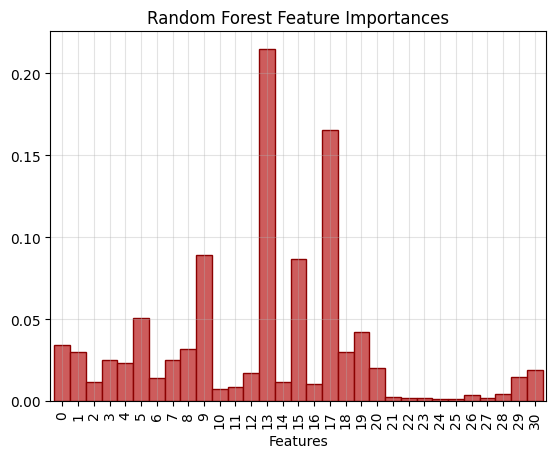

[(0.0013106686965830938, 'cat_prep_ct__Race_Asian'),
 (0.0013308829467983997, 'cat_prep_ct__Housing_Unstable'),
 (0.0015265737442979714, 'cat_prep_ct__Housing_Stable'),
 (0.0018973858877610853, 'cat_prep_ct__Race_Hispanic'),
 (0.002009914700893358, 'cat_prep_ct__Delay_Yes'),
 (0.0021749190730643566, 'cat_prep_ct__Delay_No'),
 (0.003749791145847448, 'cat_prep_ct__Race_Black'),
 (0.003997581861446563, 'cat_prep_ct__Race_White'),
 (0.007402011286159792, 'num_prep_ct__Passive'),
 (0.008308486517215077, 'num_prep_ct__Pregnant'),
 (0.010370862202805878, 'num_prep_ct__Suspicious'),
 (0.01130675034754906, 'num_prep_ct__Appetite'),
 (0.011469081210836408, 'num_prep_ct__Sleep'),
 (0.01406849679237107, 'num_prep_ct__Dep_Mood'),
 (0.014656041918398626, 'cat_prep_ct__Sex_Female'),
 (0.017349028587889732, 'num_prep_ct__Psychomotor'),
 (0.019096254897206684, 'cat_prep_ct__Sex_Male'),
 (0.020273864753069765, 'num_prep_ct__Withdrawal'),
 (0.02312948701701369, 'num_prep_ct__Content'),
 (0.02503707406345

In [73]:
def pipeline(df):
  X= df.drop(columns = ['Diagnosis', 'ID', 'Participant'])
  y = df['Diagnosis']

  num_cols = X.select_dtypes(include = ['number']).columns
  cat_cols = X.select_dtypes(include = ['object']).columns

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=23)

  num_pipe = Pipeline(steps = [
    ('num_imputer', SimpleImputer()),
    ('scaler', StandardScaler())
  ])

  cat_pipe = Pipeline(steps = [
    ('cat_imputer', SimpleImputer(strategy='constant')),
    ('encoder', OneHotEncoder(sparse_output = False))
  ])

  prep_pipe = ColumnTransformer(transformers= [
    ('num_prep_ct', num_pipe, num_cols),
    ('cat_prep_ct',cat_pipe, cat_cols)
  ]).set_output(transform="pandas")

  pipe = Pipeline(steps = [
    ('preprocessor', prep_pipe),
    ('rf_cat', RandomForestClassifier(n_estimators = 200))
  ])

  pipe.fit(X_train, y_train)
  preds = pipe.predict(X_test)

  feat_names = list(pipe[-1].feature_names_in_)
  #print(len(list(pipe[-1].feature_names_n_)))
  print(feat_names)

  feat_importances = pd.Series(pipe[-1].feature_importances_)
  plt.title('Random Forest Feature Importances')

  ticks = list(np.arange(0, 28, 1))
  labels = feat_names

  feat_importances.plot(kind = 'bar',
                      width = 1, color = 'indianred', edgecolor = 'darkred')
  plt.grid(alpha = 0.35)
  plt.xlabel('Features')
  #plt.xticks(ticks, pd.Series(labels))
  plt.show()

  #print(prep_pipe)
  #return preds
  importances =  list(zip(feat_importances, feat_names))
  return sorted(importances)

pipeline(df)

Using functions to find (1) and compare results with less dimensions (2), reduce by 6 or 7 ish

In [74]:
#drop so 20 left... 0 is first drop not number dropped
df_drop0 = df[['Rumination', '']]

TASK FOR TOMORROW: MAKE DATA FLOW

In [ ]:
#